<a href="https://colab.research.google.com/github/aranzatorres546-hash/M-TODOS-NUM-RICOS-/blob/main/dif%20divididas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Interpolación de Newton con diferencias divididas


**Curso:** Metodos Numéricos

  **Alumno:** _Aranza Citlali Rivero Torres_
  
  **Fecha:** 20 de noviembre de 2026

---



Se pide **completar la tabla de diferencias divididas**  y **construir el polinomio de interpolación** que usa todos los nodos.

| $i$ | 0 | 1 | 2 | 3 | 4 |
|:---:|:---:|:---:|:---:|:---:|:---:|
| $x_i$ | 1.0 | 1.3 | 1.6 | 1.9 | 2.2 |
| $f(x_i)$ | 0.7651977 | 0.6200860 | 0.4554022 | 0.2818186 | 0.1103623 |

Hay $n+1 = 5$ nodos, así que el polinomio es de grado $n = 4$.



Si los nodos son distintos, existe un único polinomio de grado $\le n$ que pasa por los puntos. La forma de Newton lo escribe con la base $N_i(x) = \prod_{j=0}^{i-1}(x-x_j)$:

$$P_n(x) = F_{0,0} + \sum_{i=1}^{n} F_{i,i} \prod_{j=0}^{i-1}(x - x_j)$$

**Diferencias divididas.** Los coeficientes $F_{i,i} = f[x_0,\dots,x_i]$ se obtienen de forma recursiva:

$$f[x_i] = f(x_i), \qquad f[x_i,\dots,x_{i+k}] = \frac{f[x_{i+1},\dots,x_{i+k}] - f[x_i,\dots,x_{i+k-1}]}{x_{i+k} - x_i}$$

**Algoritmo 3.2.** Con $F_{i,j} = f[x_{i-j},\dots,x_i]$ y $F_{i,0} = f(x_i)$, para $i = 1,\dots,n$ y $j = 1,\dots,i$:

$$F_{i,j} = \frac{F_{i,j-1} - F_{i-1,j-1}}{x_i - x_{i-j}}$$

La salida son los elementos de la **diagonal** $F_{0,0}, F_{1,1},\dots,F_{n,n}$.

 Al agregar un nodo solo se añade un término; los coeficientes anteriores no cambian.

In [4]:
# NOTA: usamos solo dos librerías.
#   numpy      -> arreglos (arrays) y operaciones numéricas rápidas
#   matplotlib -> para la gráfica final
import numpy as np
import matplotlib.pyplot as plt

In [5]:
# NOTA: np.array crea un arreglo; todos sus elementos son del mismo tipo (float).
# Los datos son los de la tabla 3.10 (nodos y valores de f en cada nodo).
x  = np.array([1.0, 1.3, 1.6, 1.9, 2.2])                                # x_0, ..., x_4
fx = np.array([0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623])  # f(x_0), ..., f(x_4)

# NOTA: len() cuenta los elementos. Si hay n+1 nodos, el polinomio tiene grado n.
n = len(x) - 1
print("Número de nodos:", n + 1, "  Grado del polinomio:", n)

Número de nodos: 5   Grado del polinomio: 4


In [6]:
def diferencias_divididas(x, fx):
    """Algoritmo 3.2. Devuelve la matriz F con F[i, j] = f[x_{i-j}, ..., x_i]."""
    # NOTA: 'def' define una función. El texto entre triples comillas es el docstring
    # (la descripción de lo que hace la función).
    n = len(x) - 1

    # NOTA: np.zeros((filas, columnas)) crea una matriz llena de ceros.
    # Solo vamos a llenar la parte de abajo de la diagonal (matriz triangular inferior).
    F = np.zeros((n + 1, n + 1))

    # NOTA: F[:, 0] significa "todas las filas, columna 0".
    # La primera columna son los valores de f: F[i, 0] = f(x_i).
    F[:, 0] = fx

    # NOTA: range(1, n + 1) da 1, 2, ..., n. El último número NO se incluye,
    # por eso escribimos n + 1 para que llegue hasta n.
    for i in range(1, n + 1):          # Paso 1 del algoritmo: i = 1, ..., n
        for j in range(1, i + 1):      #                       j = 1, ..., i
            # Misma fórmula del libro: F[i,j] = (F[i,j-1] - F[i-1,j-1]) / (x_i - x_{i-j})
            F[i, j] = (F[i, j-1] - F[i-1, j-1]) / (x[i] - x[i-j])
    return F

F = diferencias_divididas(x, fx)


Cada columna es un orden más: la columna $j$ contiene las diferencias divididas de orden $j$.

In [7]:
# NOTA: en un f-string, lo que va entre {} se evalúa. Por ejemplo {valor:>13.7f}
# significa "alinear a la derecha en 13 espacios, con 7 decimales".
encabezados = ["f[x_i]", "1ra dif.", "2da dif.", "3ra dif.", "4ta dif."]
print(f"{'x_i':>5}" + "".join(f"{h:>13}" for h in encabezados))

for i in range(n + 1):
    fila = f"{x[i]:>5.1f}"
    for j in range(i + 1):             # solo se imprime la parte triangular (j <= i)
        fila += f"{F[i, j]:>13.7f}"
    print(fila)

# Comprobación con el libro: la primera diferencia dividida debe ser -0.4837057
print("\nf[x0, x1] =", round(F[1, 1], 7))

  x_i       f[x_i]     1ra dif.     2da dif.     3ra dif.     4ta dif.
  1.0    0.7651977
  1.3    0.6200860   -0.4837057
  1.6    0.4554022   -0.5489460   -0.1087339
  1.9    0.2818186   -0.5786120   -0.0494433    0.0658784
  2.2    0.1103623   -0.5715210    0.0118183    0.0680685    0.0018251

f[x0, x1] = -0.4837057


 Coeficientes del polinomio:Son los elementos de la diagonal de la tabla.

In [11]:
# NOTA: np.diag extrae la diagonal principal de la matriz.
# Paso 2 del algoritmo: los coeficientes del polinomio son F[0,0], F[1,1], ..., F[n,n].
coef = np.diag(F)

for i, c in enumerate(coef):           # enumerate da el índice i junto con el valor c
    print(f"a_{i} = F[{i},{i}] = {c:.7f}")

a_0 = F[0,0] = 0.7651977
a_1 = F[1,1] = -0.4837057
a_2 = F[2,2] = -0.1087339
a_3 = F[3,3] = 0.0658784
a_4 = F[4,4] = 0.0018251


Para el  Polinomio de interpolación:
>Sustituyendo los coeficientes en la forma de Newton:

$$P_4(x) = 0.7651977 -0.4837057(x-1.0) -0.1087339(x-1.0)(x-1.3) +0.0658784(x-1.0)(x-1.3)(x-1.6) +0.0018251(x-1.0)(x-1.3)(x-1.6)(x-1.9)$$

Para evaluarlo se usa la forma anidada $a_0 + (x-x_0)\big(a_1 + (x-x_1)(a_2 + \cdots)\big)$, que necesita menos multiplicaciones.

In [8]:
def newton_eval(t, x, coef):
    """Evalúa P_n(t) en forma anidada (como en el método de Horner)."""
    # NOTA: en vez de calcular cada producto (t-x_0)(t-x_1)... por separado,
    # se agrupa:  a_0 + (t-x_0)*(a_1 + (t-x_1)*(a_2 + ...)) y se evalúa de adentro hacia afuera.
    t = np.asarray(t, dtype=float)             # permite pasar un número o un arreglo
    P = coef[-1] * np.ones_like(t)             # coef[-1] es el ÚLTIMO elemento (a_n)
    for k in range(len(coef) - 2, -1, -1):     # k = n-1, n-2, ..., 0  (el -1 final es el paso: hacia atrás)
        P = P * (t - x[k]) + coef[k]
    return P

##Verificación y gráfica
Se comprueba que $P_4(x_i) = f(x_i)$ en los nodos y que coincide con el polinomio de `np.polyfit` (la unicidad lo exige). Las diferencias deben ser del orden del error de redondeo.

In [12]:
# NOTA: si el polinomio es correcto, debe valer f(x_i) en cada nodo (condición de interpolación).
P_nodos = newton_eval(x, x, coef)
print("P_4(x_i) :", np.round(P_nodos, 7))
print("f(x_i)   :", fx)
print("Error máximo en los nodos:", np.max(np.abs(P_nodos - fx)))

# NOTA: el polinomio de grado 4 que pasa por 5 puntos es ÚNICO, así que debe coincidir
# con el que calcula np.polyfit (que usa otro método). Comparamos en muchos puntos.
t = np.linspace(0.9, 2.3, 400)
dif = np.max(np.abs(newton_eval(t, x, coef) - np.polyval(np.polyfit(x, fx, 4), t)))
print("Diferencia máxima con np.polyfit:", dif)

P_4(x_i) : [0.7651977 0.620086  0.4554022 0.2818186 0.1103623]
f(x_i)   : [0.7651977 0.620086  0.4554022 0.2818186 0.1103623]
Error máximo en los nodos: 2.7755575615628914e-17
Diferencia máxima con np.polyfit: 1.6653345369377348e-15


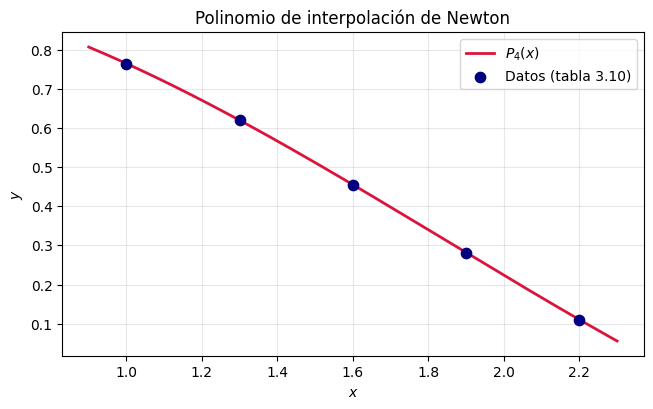

In [13]:
# NOTA: np.linspace(a, b, m) genera m puntos igualmente espaciados entre a y b.
t = np.linspace(0.9, 2.3, 400)

plt.figure(figsize=(7.5, 4.2))
plt.plot(t, newton_eval(t, x, coef), color="crimson", lw=2, label=r"$P_4(x)$")   # curva del polinomio
plt.scatter(x, fx, color="navy", zorder=3, s=55, label="Datos (tabla 3.10)")    # puntos dados
plt.xlabel("$x$"); plt.ylabel("$y$")
plt.title("Polinomio de interpolación de Newton")
plt.grid(alpha=0.3); plt.legend()
plt.show()



Hasta aquí todo fue numérico. Con **SymPy** se puede escribir $P_4(x)$ como una expresión en la variable $x$, **desarrollarla en potencias** y comprobar que sus coeficientes coinciden con los de `np.polyfit`, que usa otro método. Es una verificación independiente de la tabla de diferencias divididas.

> **Nota:** estas celdas requieren SymPy,deben ejecutarse **después** de las celdas anteriores, porque usan `x`, `fx`, `n` y `coef`.

In [14]:
# NOTA: SymPy es una librería de álgebra simbólica: trabaja con fórmulas exactas,
# no solo con números. Aquí la usamos para escribir P_4(x) como expresión en x.
import sympy as sp
sp.init_printing()            # hace que Jupyter muestre las fórmulas en LaTeX

X = sp.symbols("x")           # X es una variable simbólica (no tiene valor numérico)

# NOTA: sp.Rational("1.3") guarda 1.3 como la fracción exacta 13/10 (sin error de redondeo).
nodos = [sp.Rational(str(xi)) for xi in x]

# Construimos P_4(x) = a_0 + a_1 N_1(x) + ... + a_4 N_4(x) con la base de Newton
# N_i(x) = (x - x_0)(x - x_1)...(x - x_{i-1}), igual que en la fórmula del libro.
P_sym = sp.Float(coef[0], 15)      # a_0
base = sp.Integer(1)               # N_0(x) = 1
for i in range(1, n + 1):
    base = base * (X - nodos[i - 1])               # N_i = N_{i-1} * (x - x_{i-1})
    P_sym = P_sym + sp.Float(coef[i], 15) * base   # suma a_i * N_i(x)

P_sym      # al final de la celda, Jupyter muestra la fórmula (forma de Newton)

                                           ⎛    19⎞           ⎛    13⎞         ↪
-0.483705666666666⋅x + 0.00182510288066044⋅⎜x - ──⎟⋅(x - 8/5)⋅⎜x - ──⎟⋅(x - 1) ↪
                                           ⎝    10⎠           ⎝    10⎠         ↪

↪                                 ⎛    13⎞                             ⎛    13 ↪
↪  + 0.0658783950617283⋅(x - 8/5)⋅⎜x - ──⎟⋅(x - 1) - 0.108733888888889⋅⎜x - ── ↪
↪                                 ⎝    10⎠                             ⎝    10 ↪

↪ ⎞                           
↪ ⎟⋅(x - 1) + 1.24890336666667
↪ ⎠                           

In [15]:
# NOTA: sp.expand desarrolla los productos y agrupa por potencias de x.
P_exp = sp.expand(P_sym)
display(P_exp)

# NOTA: sp.Poly(...).all_coeffs() devuelve los coeficientes de MAYOR a menor grado,
# el mismo orden que usa np.polyfit, así que se pueden comparar directamente.
coef_sympy = [float(c) for c in sp.Poly(P_exp, X).all_coeffs()]
coef_polyfit = np.polyfit(x, fx, 4)
print("Coeficientes (SymPy)  :", np.round(coef_sympy, 7))
print("Coeficientes (polyfit):", np.round(coef_polyfit, 7))
print("¿Coinciden?", np.allclose(coef_sympy, coef_polyfit, atol=1e-8))

# NOTA: .subs(variable, valor) sustituye la variable simbólica por un número.
print("P_4(1.5) =", float(P_exp.subs(X, 1.5)))

                     4                       3                      2          ↪
0.00182510288066044⋅x  + 0.0552927983538978⋅x  - 0.343046604938247⋅x  + 0.0733 ↪

↪                                   
↪ 913477366034⋅x + 0.977735055967085

Coeficientes (SymPy)  : [ 0.0018251  0.0552928 -0.3430466  0.0733913  0.9777351]
Coeficientes (polyfit): [ 0.0018251  0.0552928 -0.3430466  0.0733913  0.9777351]
¿Coinciden? True
P_4(1.5) = 0.5118199942386834




> ### Resultado
> **Coeficientes (diagonal):** 0.7651977, -0.4837057, -0.1087339, 0.0658784, 0.0018251
>
> **Polinomio de interpolación de grado 4 (forma de Newton):**
>
> $$\boxed{P_4(x) = 0.7651977 -0.4837057(x-1.0) -0.1087339(x-1.0)(x-1.3) +0.0658784(x-1.0)(x-1.3)(x-1.6) +0.0018251(x-1.0)(x-1.3)(x-1.6)(x-1.9)}$$
>
> **Forma desarrollada:**
>
> $$P_4(x) = 0.9777351 +0.0733913x -0.3430466x^2 +0.0552928x^3 +0.0018251x^4$$

**Conclusión.** La tabla se completó con el algoritmo 3.2 y el polinomio reproduce los cinco datos (error de redondeo). La primera diferencia dividida, $f[x_0,x_1] = -0.4837057$, coincide con el libro.